In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
CWD = Path.cwd()
timing_dir = CWD / "timing_results"
sub_timing_dirs = timing_dir / "individual_runs"
gpu_jsons = list(sub_timing_dirs.glob("gpu_*.json"))
cpu_jsons = list(sub_timing_dirs.glob("cpu_*.json"))
gpu_data = []
for gpu_json in gpu_jsons:
    with open(gpu_json, "r") as f:
        gpu_data.append(json.load(f))

cpu_data = []
for cpu_json in cpu_jsons:
    with open(cpu_json, "r") as f:
        cpu_data.append(json.load(f))

summary = []
for gpu_datum in gpu_data:
    found_idx = None
    for idx, cpu_datum in enumerate(cpu_data):
        cond1 = gpu_datum["n_size"] == cpu_datum["n_size"]
        cond2 = gpu_datum["dimension"] == cpu_datum["dimension"]
        cond3 = gpu_datum["tolerance"] == cpu_datum["tolerance"]
        if cond1 and cond2 and cond3:
            found_idx = idx
            break
    if found_idx is not None:
        cpu_datum = cpu_data[found_idx]
        speedup = cpu_datum["cpu_time_seconds"] / gpu_datum["gpu_time_seconds"]
        summary.append(
            {
                "n_size": gpu_datum["n_size"],
                "dimension": gpu_datum["dimension"],
                "tolerance": gpu_datum["tolerance"],
                "cpu_time_seconds": cpu_datum["cpu_time_seconds"],
                "gpu_time_seconds": gpu_datum["gpu_time_seconds"],
                "speedup": speedup,
                "gpu_num_clusters": gpu_datum["gpu_num_clusters"],
                "cpu_num_clusters": cpu_datum["cpu_num_clusters"],
            }
        )
    else:
        # Append only gpu with nan for cpu
        summary.append(
            {
                "n_size": gpu_datum["n_size"],
                "dimension": gpu_datum["dimension"],
                "tolerance": gpu_datum["tolerance"],
                "cpu_time_seconds": np.nan,
                "gpu_time_seconds": gpu_datum["gpu_time_seconds"],
                "speedup": np.nan,
                "gpu_num_clusters": gpu_datum["gpu_num_clusters"],
                "cpu_num_clusters": np.nan,
            }
        )
df = pd.DataFrame(summary)
df.sort_values(by=["tolerance", "dimension", "n_size"], inplace=True)
df.reset_index(drop=True, inplace=True)

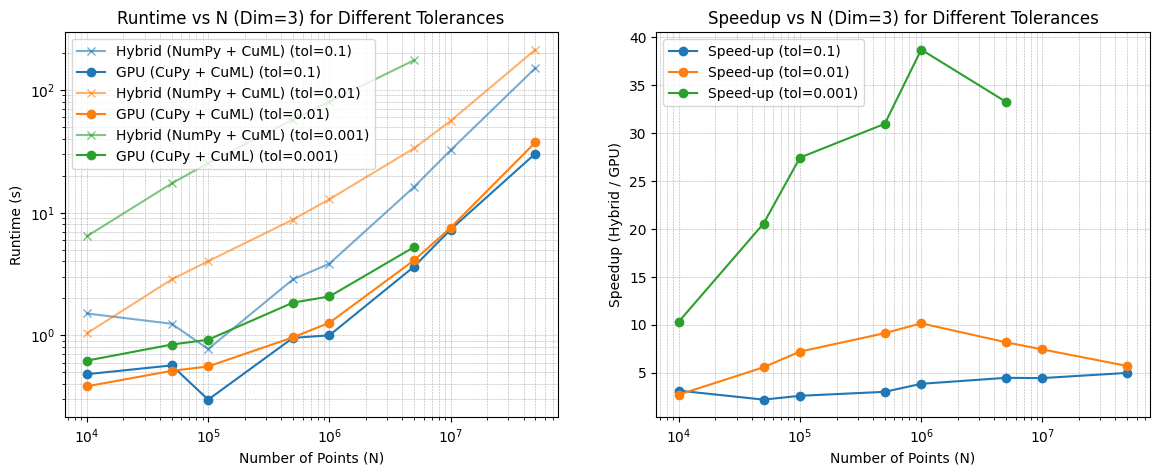

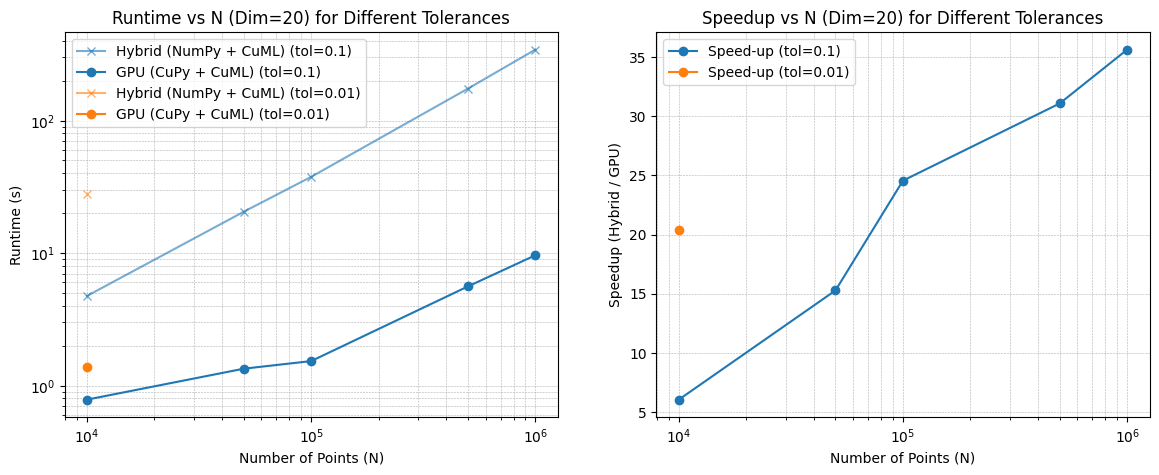

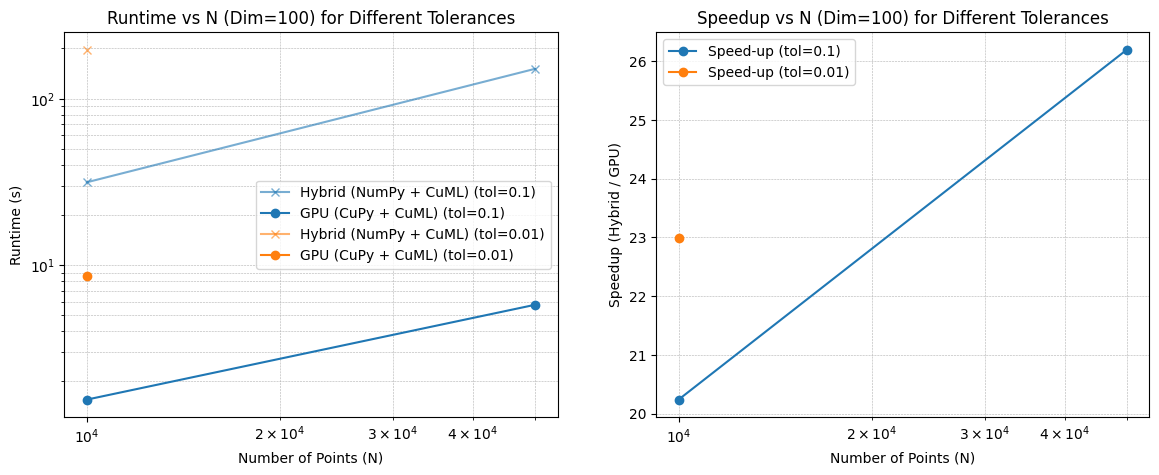

In [ ]:
grid_alpha = 0.4
for dim in sorted(df["dimension"].unique(), reverse=False):
    dim_df = df[df["dimension"] == dim]
    sorted_tols = sorted(dim_df["tolerance"].unique(), reverse=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

    colors = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7"]
    for i, tol in enumerate(sorted_tols):
        _c = colors[i % len(colors)]
        tol_df = dim_df[dim_df["tolerance"] == tol]
        tol_df = tol_df.sort_values(by="n_size")

        ax1.plot(
            tol_df["n_size"],
            tol_df["cpu_time_seconds"],
            marker="x",
            label=f"Hybrid (NumPy + CuML) (tol={tol})",
            color=_c,
            alpha=0.6,
        )
        ax1.plot(
            tol_df["n_size"],
            tol_df["gpu_time_seconds"],
            marker="o",
            label=f"GPU (CuPy + CuML) (tol={tol})",
            color=_c,
            alpha=1.0,
        )
        speed_up = tol_df["cpu_time_seconds"] / tol_df["gpu_time_seconds"]
        ax2.plot(
            tol_df["n_size"],
            speed_up,
            marker="o",
            label=f"Speed-up (tol={tol})",
            color=_c,
            alpha=1.0,
        )
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel("Number of Initial Points (N)")
    ax1.set_ylabel("Runtime (s)")
    ax1.set_title(f"Runtime vs N (Dim={dim}) for Different Tolerances")
    ax1.legend()
    ax1.grid(True, which="both", ls="--", lw=grid_alpha)

    ax2.set_xscale("log")
    ax2.set_xlabel("Number of Initial Points (N)")
    ax2.set_ylabel("Speedup (Hybrid / GPU)")
    ax2.set_title(f"Speedup vs N (Dim={dim}) for Different Tolerances")
    ax2.legend()
    ax2.grid(True, which="both", ls="--", lw=grid_alpha)

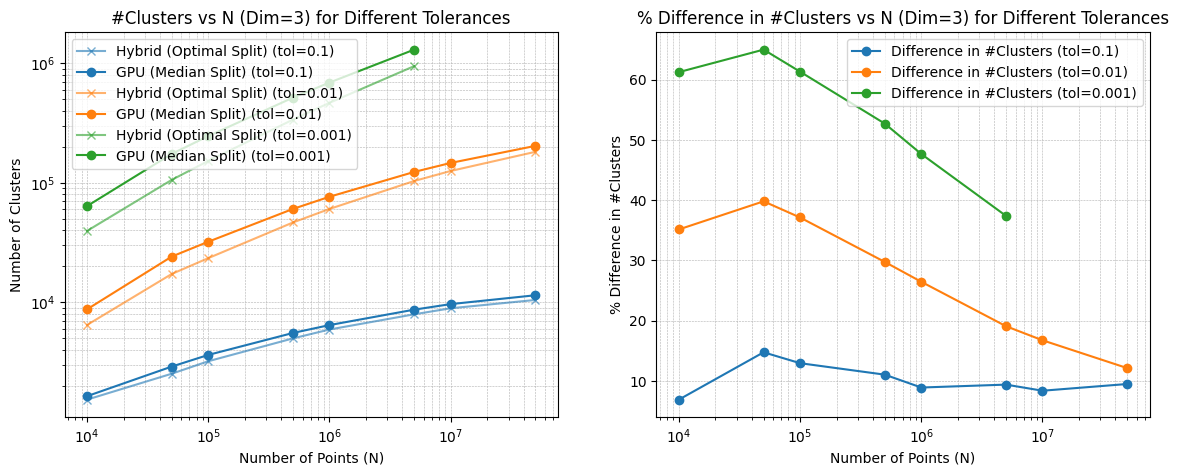

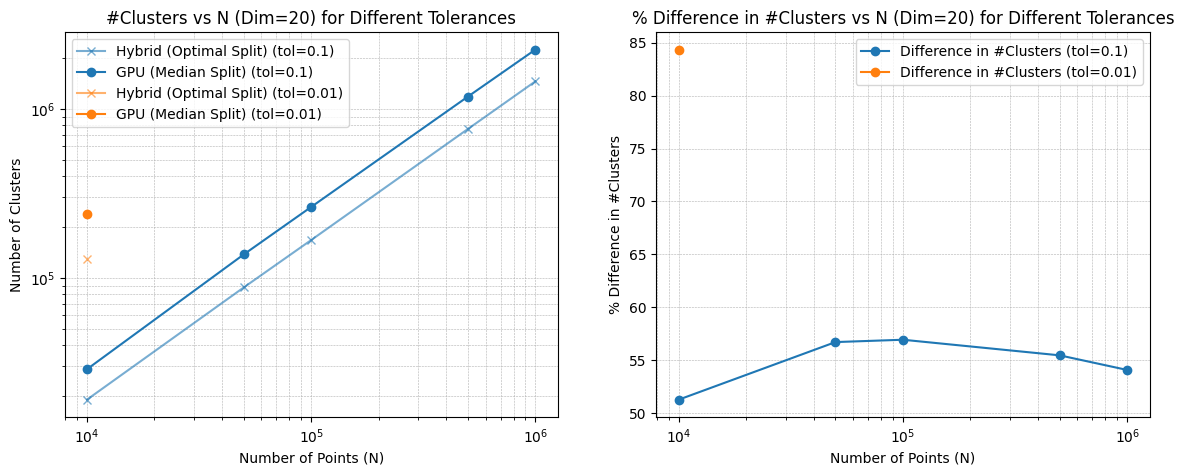

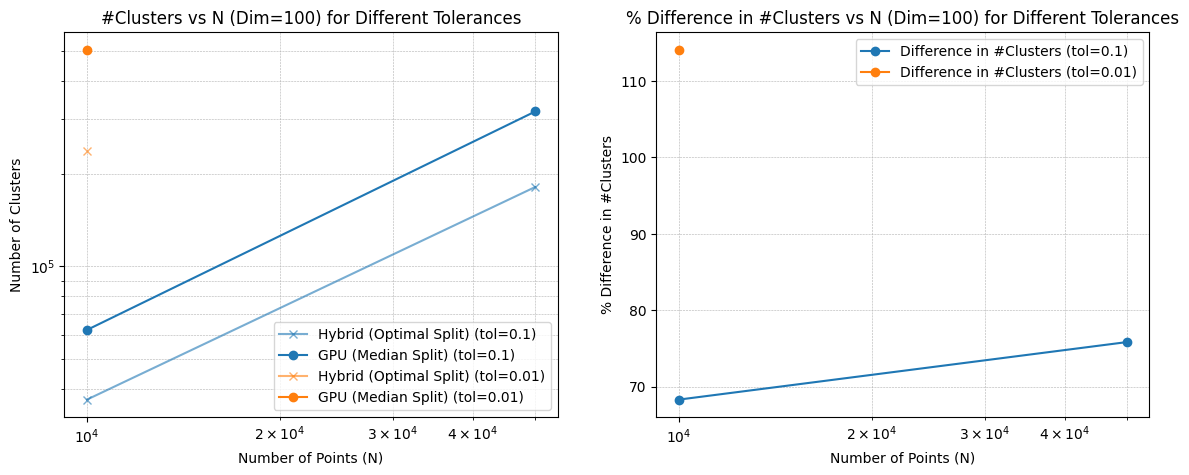

In [ ]:
grid_alpha = 0.4
for dim in sorted(df["dimension"].unique()):
    dim_df = df[df["dimension"] == dim]
    sorted_tols = sorted(dim_df["tolerance"].unique(), reverse=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    colors = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7"]
    for i, tol in enumerate(sorted_tols):
        _c = colors[i % len(colors)]
        tol_df = dim_df[dim_df["tolerance"] == tol]
        tol_df = tol_df.sort_values(by="n_size")

        if "optimal" in timing_dir.name:
            label = f"Hybrid (Optimal Split) (tol={tol})"
        else:
            label = f"Hybrid (Median Split) (tol={tol})"

        ax1.plot(
            tol_df["n_size"],
            tol_df["cpu_num_clusters"],
            marker="x",
            label=label,
            color=_c,
            alpha=0.6,
        )
        ax1.plot(
            tol_df["n_size"],
            tol_df["gpu_num_clusters"],
            marker="o",
            label=f"GPU (Median Split) (tol={tol})",
            color=_c,
            alpha=1.0,
        )
        diff = abs(tol_df["gpu_num_clusters"] - tol_df["cpu_num_clusters"])
        rel_diff = 100 * diff / tol_df["cpu_num_clusters"]
        ax2.plot(
            tol_df["n_size"],
            rel_diff,
            marker="o",
            label=f"Difference in #Clusters (tol={tol})",
            color=_c,
            alpha=1.0,
        )
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel("Number of Initial Points (N)")
    ax1.set_ylabel("Number of Clusters")
    ax1.set_title(f"#Clusters vs N (Dim={dim}) for Different Tolerances")
    ax1.legend()
    ax1.grid(True, which="both", ls="--", lw=grid_alpha)

    ax2.set_xscale("log")
    ax2.set_xlabel("Number of Initial Points (N)")
    ax2.set_ylabel("% Difference in #Clusters")
    ax2.set_title(
        f"% Difference in #Clusters vs N (Dim={dim}) for Different Tolerances"
    )
    ax2.legend()
    ax2.grid(True, which="both", ls="--", lw=grid_alpha)

## TODO
- [ ] Solve `CUDA - Out of Memory` issue for larger datasets, particularly when `dim>=10`
- [ ] More analysis on the centroids obtained from `optimal` vs `median` splits
  - [ ] Implement `optimal` split on GPU if required?